# Simple MLP autoencoder — one dataset per run

Choose your dataset folder and latent size, then run the cells in order. Each input folder contains the already preprocessed `train.parquet`, `val.parquet`, and `test.parquet` files.

**Features → 64 → 32 → latent_dim → 32 → 64 → reconstructed features**

Train one independent model at a time. Save the autoencoder, encoder, and all three encoded splits. Small batches let you use the complete datasets without loading them into RAM together.

## 1. Settings and data

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/notebooks/omarahmed001/cic-preprocessing/__notebook__.ipynb
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/__output__.json
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/__results__.html
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/custom.css
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_IterativeImputer/README.md
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_IterativeImputer/preprocessor.joblib
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_IterativeImputer/test.parquet
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_IterativeImputer/train.parquet
/kaggle/input/notebooks/omarahmed001/cic-preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_It

In [28]:
from pathlib import Path
import math
import json
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# In Colab, uncomment these lines to access Drive:
# from google.colab import drive
# drive.mount('/content/drive')

In [29]:
DATASET = 'NF_TON_IOT'  # Change for each run.
INPUT_DIR = Path('/kaggle/input/notebooks/omarahmed001/preprocessing/project/outputs/CIC-BoT-IoT/preprocessing/20261110_all_attacks_IterativeImputer')
LATENT_DIM = 16
BATCH_SIZE = 2048
EPOCHS = 20

OUTPUT_DIR = Path('/kaggle/working/outputs') / DATASET / 'autoencoder' / f'latent_{LATENT_DIM}'
# On Kaggle, set INPUT_DIR to your attached splits and OUTPUT_DIR under /kaggle/working.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

feature_columns = [c for c in pq.ParquetFile(INPUT_DIR / 'train_adasyn_tomek.parquet').schema_arrow.names
                   if c not in ['Label', 'Attack', 'Dataset']]
input_dim = len(feature_columns)
print(DATASET, '| input features:', input_dim, '| latent features:', LATENT_DIM)

NF_TON_IOT | input features: 486 | latent features: 16


In [30]:
# Each autoencoder input is also its reconstruction target: (X, X).
def read_batches(split):
    file = pq.ParquetFile(INPUT_DIR / f'{split}.parquet')
    for batch in file.iter_batches(batch_size=BATCH_SIZE, columns=feature_columns):
        X = batch.to_pandas().to_numpy(dtype=np.float64)
        yield X, X

signature = (tf.TensorSpec((None, input_dim), tf.float64),
             tf.TensorSpec((None, input_dim), tf.float64))
train_data = tf.data.Dataset.from_generator(lambda: read_batches('train'), output_signature=signature).repeat().prefetch(1)
val_data = tf.data.Dataset.from_generator(lambda: read_batches('val'), output_signature=signature).prefetch(1)
train_steps = math.ceil(pq.ParquetFile(INPUT_DIR / 'train.parquet').metadata.num_rows / BATCH_SIZE)
val_steps = math.ceil(pq.ParquetFile(INPUT_DIR / 'val.parquet').metadata.num_rows / BATCH_SIZE)

## 2. Build and train

Choose the latent size with `LATENT_DIM`. The latent and output layers are linear because your scaled features can be negative. `Label` and `Attack` are not model inputs. Validation data are used for the learning curves and early stopping.

In [31]:
def build_autoencoder(input_dim, latent_dim):
    inputs = keras.Input(shape=(input_dim,))
    x = layers.Dense(64, activation='relu')(inputs)
    x = layers.Dense(32, activation='relu')(x)
    latent = layers.Dense(latent_dim, activation='linear', name='latent')(x)

    x = layers.Dense(32, activation='relu')(latent)
    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(input_dim, activation='linear')(x)

    autoencoder = keras.Model(inputs, outputs, name='autoencoder')
    encoder = keras.Model(inputs, latent, name='encoder')
    return autoencoder, encoder

keras.backend.clear_session()
keras.utils.set_random_seed(42)
autoencoder, encoder = build_autoencoder(input_dim, LATENT_DIM)
autoencoder.compile(optimizer='adam', loss='mse', metrics=['mae'])
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 486)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        31,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 486)            │        31,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,022 (265.71 KB)

 Trainable params: 68,022 (265.71 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history = autoencoder.fit(
    train_data,
    steps_per_epoch=train_steps,
    validation_data=val_data,
    validation_steps=val_steps,
    epochs=EPOCHS,
    callbacks=[
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True
        ),
    ],
    shuffle=False,
    verbose=2,
)

Epoch 1/20
Batch 14: Invalid loss, terminating training
4124/4124 - 35s - 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan


## 3. Plot metrics and save the models

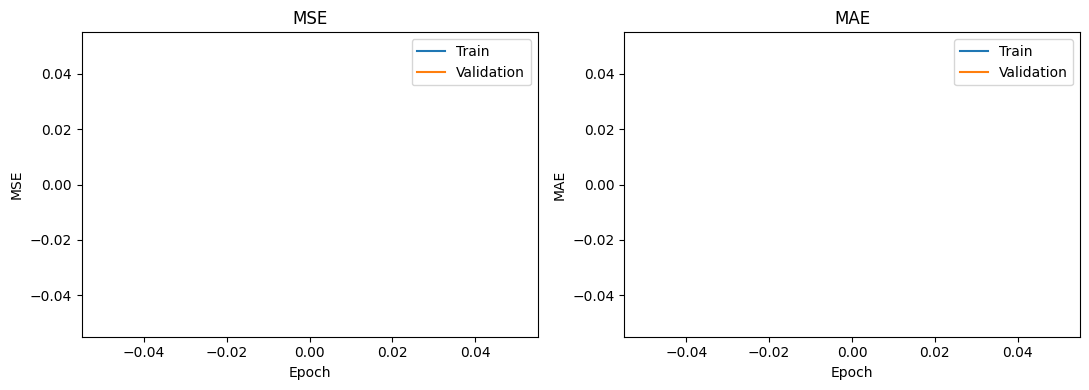

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ['loss', 'mae'], ['MSE', 'MAE']):
    ax.plot(range(1, len(history.history[metric]) + 1), history.history[metric], label='Train')
    ax.plot(range(1, len(history.history[metric]) + 1), history.history[f'val_{metric}'], label='Validation')
    ax.set(xlabel='Epoch', ylabel=title, title=title)
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_metrics.png')
plt.show()
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

In [8]:
test_data = tf.data.Dataset.from_generator(lambda: read_batches('test'), output_signature=signature).prefetch(1)
test_steps = math.ceil(pq.ParquetFile(INPUT_DIR / 'test.parquet').metadata.num_rows / BATCH_SIZE)
test_metrics = autoencoder.evaluate(test_data, steps=test_steps, return_dict=True, verbose=0)
print('Test MSE:', test_metrics['loss'], '| Test MAE:', test_metrics['mae'])
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)

autoencoder.save(OUTPUT_DIR / 'autoencoder.keras')
encoder.save(OUTPUT_DIR / 'encoder.keras')
(OUTPUT_DIR / 'feature_columns.json').write_text(json.dumps(feature_columns, indent=2))

Test MSE: nan | Test MAE: nan


17421

## 4. Encode and save train, validation, and test

Encode each split in its original row order. The saved Parquet files contain `z_0 … z_(LATENT_DIM-1)` as float32, plus the original `Label` and `Attack` columns. Zstandard compresses the output files.

In [9]:
for split in ['train', 'val', 'test']:
    source = pq.ParquetFile(INPUT_DIR / f'{split}.parquet')
    latent_columns = [f'z_{i}' for i in range(LATENT_DIM)]
    schema = pa.schema([(c, pa.float32()) for c in latent_columns]
                       + [source.schema_arrow.field(c) for c in ['Label', 'Attack']])

    with pq.ParquetWriter(OUTPUT_DIR / f'{split}_encoded.parquet', schema, compression='zstd') as writer:
        for batch in source.iter_batches(batch_size=BATCH_SIZE):
            df = batch.to_pandas()
            X = df[feature_columns].to_numpy(dtype=np.float32)
            Z = encoder(X, training=False).numpy()
            encoded = pd.DataFrame(Z, columns=latent_columns)
            encoded['Label'] = df['Label'].to_numpy()
            encoded['Attack'] = df['Attack'].to_numpy()
            writer.write_table(pa.Table.from_pandas(encoded, schema=schema, preserve_index=False))
    print('Saved:', OUTPUT_DIR / f'{split}_encoded.parquet')

/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeW

Saved: /kaggle/working/outputs/NF_TON_IOT/autoencoder/latent_16/train_encoded.parquet


/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr


Saved: /kaggle/working/outputs/NF_TON_IOT/autoencoder/latent_16/val_encoded.parquet


/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/managers.py:1772: RuntimeWarning: overflow encountered in cast
  result[rl.indexer] = arr


Saved: /kaggle/working/outputs/NF_TON_IOT/autoencoder/latent_16/test_encoded.parquet


Run the notebook again with another `DATASET` and `INPUT_DIR` to train that dataset's own autoencoder. Use the same `LATENT_DIM` if you want the same encoded width. These independently trained encoders do not yet align the datasets into a shared latent space.

To use a saved encoder later:

In [10]:
# encoder = keras.models.load_model(OUTPUT_DIR / 'encoder.keras')
# feature_columns = json.loads((OUTPUT_DIR / 'feature_columns.json').read_text())
# Z = encoder(prepared_batch[feature_columns].to_numpy(dtype=np.float32), training=False).numpy()

## TEST — diagnose NaN results

Run this section after the imports and path settings in Section 1. You can skip building, training, and saving the model above: these tests load your existing `autoencoder.keras` and `feature_columns.json`.

Set `RUN_TESTS = True`, check `TEST_MODEL_DIR` and `INPUT_DIR`, then run the TEST cells in order. The full scan reads every training and validation batch and may take a few minutes. Tests do not change the saved model or dataset files. Outputs are printed below each cell.

The optional fresh-training probe is disabled separately. Use it if the other tests do not explain the failure; it creates a separate model and stops at the first numerical failure. Do not save or encode with a model whose weights or predictions contain NaNs/infinities.

In [23]:
RUN_TESTS = True  # Set True to run this section.
RUN_TRAINING_PROBE = False  # Optional; set True only for Test 4.
TEST_MODEL_DIR = OUTPUT_DIR  # Folder containing your saved model and feature list.
TEST_SPLITS = ['train', 'val']

if RUN_TESTS:
    test_model = keras.models.load_model(
        TEST_MODEL_DIR / 'autoencoder.keras', compile=False
    )
    test_feature_columns = json.loads(
        (TEST_MODEL_DIR / 'feature_columns.json').read_text()
    )
    print('TensorFlow:', tf.__version__)
    print('Loaded model:', TEST_MODEL_DIR / 'autoencoder.keras')
    print('Input/output shapes:', test_model.input_shape, test_model.output_shape)
    print('Model dtype policy:', test_model.dtype_policy)

TensorFlow: 2.20.0
Loaded model: /kaggle/working/outputs/NF_TON_IOT/autoencoder/latent_16/autoencoder.keras
Input/output shapes: (None, 486) (None, 486)
Model dtype policy: <DTypePolicy "float32">


### Test 1 — saved weights

NaNs/infinities here confirm that invalid parameters were saved. Finite weights can still overflow during computation, so also check the sample and the full data scan.

In [24]:
if RUN_TESTS:
    weight_results = []
    for layer in test_model.layers:
        for variable in layer.weights:
            values = variable.numpy()
            finite_values = values[np.isfinite(values)]
            weight_results.append({
                'Layer': layer.name,
                'Weight': variable.name,
                'NaNs': int(np.isnan(values).sum()),
                'Infinities': int(np.isinf(values).sum()),
                'Largest_finite_abs': (
                    float(np.abs(finite_values).max())
                    if finite_values.size else np.nan
                ),
            })
    display(pd.DataFrame(weight_results))

,Layer,Weight,NaNs,Infinities,Largest_finite_abs
0,dense,kernel,128,0,0.127273
1,dense,bias,0,0,0.024891
2,dense_1,kernel,2048,0,NaN
3,dense_1,bias,0,0,0.024739
4,latent,kernel,512,0,NaN
5,latent,bias,16,0,NaN
6,dense_2,kernel,512,0,NaN
7,dense_2,bias,0,0,0.026157
8,dense_3,kernel,2048,0,NaN
9,dense_3,bias,0,0,0.026131


### Test 2 — sample inputs, reconstruction, and each layer

Read five training examples, compare them with their reconstructions, then show where nonfinite activations first appear. Float64 below preserves the source values for diagnosis; the model still receives float32, matching normal training. A clean sample does not rule out a bad batch elsewhere.

In [25]:
if RUN_TESTS:
    sample_file = pq.ParquetFile(INPUT_DIR / 'train.parquet')
    sample_batch = next(sample_file.iter_batches(
        batch_size=5, columns=test_feature_columns
    ))
    test_X64 = sample_batch.to_pandas().to_numpy(dtype=np.float64)
    with np.errstate(over='ignore', invalid='ignore'):
        test_X = test_X64.astype(np.float32)
    test_reconstructed = test_model(test_X, training=False).numpy()

    sample_results = []
    for name, values in [
        ('Source float64', test_X64),
        ('Model input float32', test_X),
        ('Reconstruction', test_reconstructed),
    ]:
        finite_values = values[np.isfinite(values)]
        sample_results.append({
            'Stage': name,
            'NaNs': int(np.isnan(values).sum()),
            'Infinities': int(np.isinf(values).sum()),
            'Largest_finite_abs': (
                float(np.abs(finite_values).max())
                if finite_values.size else np.nan
            ),
        })
    display(pd.DataFrame(sample_results))

    sample_index = 0  # Choose 0, 1, 2, 3, or 4.
    display(pd.DataFrame({
        'Input': test_X[sample_index],
        'Reconstructed': test_reconstructed[sample_index],
        'Absolute_error': np.abs(
            test_X[sample_index] - test_reconstructed[sample_index]
        ),
    }, index=test_feature_columns))

    layer_probe = keras.Model(
        test_model.inputs, [layer.output for layer in test_model.layers]
    )
    layer_results = []
    for layer, output in zip(
        test_model.layers, layer_probe(test_X, training=False)
    ):
        values = output.numpy()
        finite_values = values[np.isfinite(values)]
        layer_results.append({
            'Layer': layer.name,
            'NaNs': int(np.isnan(values).sum()),
            'Infinities': int(np.isinf(values).sum()),
            'Largest_finite_abs': (
                float(np.abs(finite_values).max())
                if finite_values.size else np.nan
            ),
        })
    display(pd.DataFrame(layer_results))

,Stage,NaNs,Infinities,Largest_finite_abs
0,Source float64,0,0,2.513216
1,Model input float32,0,0,2.513216
2,Reconstruction,2430,0,NaN


,Input,Reconstructed,Absolute_error
numbers__IN_BYTES,-0.010602,NaN,NaN
numbers__IN_PKTS,-0.009171,NaN,NaN
numbers__OUT_BYTES,-0.007564,NaN,NaN
numbers__OUT_PKTS,-0.014757,NaN,NaN
numbers__FLOW_DURATION_MILLISECONDS,-0.567983,NaN,NaN
...,...,...,...
categories__ICMP_CODE_DECODED_1,0.000000,NaN,NaN
categories__ICMP_CODE_DECODED_2,0.000000,NaN,NaN
categories__ICMP_CODE_DECODED_3,0.000000,NaN,NaN
categories__ICMP_CODE_DECODED_5,0.000000,NaN,NaN


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(5, 486))
  warnings.warn(msg)


,Layer,NaNs,Infinities,Largest_finite_abs
0,input_layer,0,0,2.513216
1,dense,320,0,NaN
2,dense_1,160,0,NaN
3,latent,80,0,NaN
4,dense_2,160,0,NaN
5,dense_3,320,0,NaN
6,dense_4,2430,0,NaN


### Test 3 — scan every training and validation batch

Report existing NaNs/infinities, finite source values that overflow float32, and the largest finite magnitudes. Counts refer to individual feature values, not rows. The first affected batch uses numbering starting at 1. Very large finite values can also overflow the model or MSE even if they fit float32; the magnitude table helps identify them. This test does not clean, clip, or replace values.

In [26]:
if RUN_TESTS:
    float32_limit = float(np.finfo(np.float32).max)
    for split in TEST_SPLITS:
        print(f'\nScanning {split}...')
        file = pq.ParquetFile(INPUT_DIR / f'{split}.parquet')
        nan_counts = np.zeros(len(test_feature_columns), dtype=np.int64)
        inf_counts = np.zeros(len(test_feature_columns), dtype=np.int64)
        outside_counts = np.zeros(len(test_feature_columns), dtype=np.int64)
        max_abs = np.zeros(len(test_feature_columns), dtype=np.float64)
        first_bad_batch = None

        for batch_number, batch in enumerate(file.iter_batches(
            batch_size=BATCH_SIZE, columns=test_feature_columns
        ), start=1):
            values = batch.to_pandas().to_numpy(dtype=np.float64)
            finite = np.isfinite(values)
            magnitude = np.abs(values)
            outside = finite & (magnitude > float32_limit)
            nan_counts += np.isnan(values).sum(axis=0)
            inf_counts += np.isinf(values).sum(axis=0)
            outside_counts += outside.sum(axis=0)
            max_abs = np.maximum(
                max_abs, np.where(finite, magnitude, 0).max(axis=0)
            )
            if first_bad_batch is None and ((~finite).any() or outside.any()):
                first_bad_batch = batch_number
            if batch_number % 1000 == 0:
                print('Batches scanned:', batch_number)

        report = pd.DataFrame({
            'NaNs': nan_counts,
            'Infinities': inf_counts,
            'Outside_float32': outside_counts,
            'Largest_finite_abs': max_abs,
        }, index=test_feature_columns)
        print('Total problematic values:')
        print(report[['NaNs', 'Infinities', 'Outside_float32']].sum())
        print('First batch with nonfinite/out-of-range inputs:', first_bad_batch)
        print('Affected columns:')
        display(report.loc[
            report[['NaNs', 'Infinities', 'Outside_float32']].gt(0).any(axis=1)
        ])
        print('10 columns with largest finite magnitudes:')
        display(report.nlargest(10, 'Largest_finite_abs'))


Scanning train...
Batches scanned: 1000
Batches scanned: 2000
Batches scanned: 3000
Batches scanned: 4000
Total problematic values:
NaNs                0
Infinities          0
Outside_float32    26
dtype: int64
First batch with nonfinite/out-of-range inputs: 15
Affected columns:


,NaNs,Infinities,Outside_float32,Largest_finite_abs
numbers__SRC_TO_DST_SECOND_BYTES,0,0,17,8.078126e+247
numbers__DST_TO_SRC_SECOND_BYTES,0,0,9,6.261777e+177


10 columns with largest finite magnitudes:


,NaNs,Infinities,Outside_float32,Largest_finite_abs
numbers__SRC_TO_DST_SECOND_BYTES,0,0,17,8.078126e+247
numbers__DST_TO_SRC_SECOND_BYTES,0,0,9,6.261777e+177
numbers__RETRANSMITTED_OUT_BYTES,0,0,0,5.746570e+03
numbers__IN_BYTES,0,0,0,3.575054e+03
numbers__RETRANSMITTED_OUT_PKTS,0,0,0,2.757245e+03
numbers__NUM_PKTS_128_TO_256_BYTES,0,0,0,2.089747e+03
numbers__NUM_PKTS_256_TO_512_BYTES,0,0,0,1.867886e+03
numbers__OUT_PKTS,0,0,0,1.865224e+03
numbers__NUM_PKTS_1024_TO_1514_BYTES,0,0,0,1.644621e+03
numbers__RETRANSMITTED_IN_BYTES,0,0,0,1.562213e+03



Scanning val...
Total problematic values:
NaNs               0
Infinities         0
Outside_float32    8
dtype: int64
First batch with nonfinite/out-of-range inputs: 318
Affected columns:


,NaNs,Infinities,Outside_float32,Largest_finite_abs
numbers__SRC_TO_DST_SECOND_BYTES,0,0,6,5.009692e+181
numbers__DST_TO_SRC_SECOND_BYTES,0,0,2,1.970040e+108


10 columns with largest finite magnitudes:


,NaNs,Infinities,Outside_float32,Largest_finite_abs
numbers__SRC_TO_DST_SECOND_BYTES,0,0,6,5.009692e+181
numbers__DST_TO_SRC_SECOND_BYTES,0,0,2,1.970040e+108
numbers__RETRANSMITTED_OUT_BYTES,0,0,0,4.843533e+03
numbers__NUM_PKTS_128_TO_256_BYTES,0,0,0,2.903632e+03
numbers__RETRANSMITTED_OUT_PKTS,0,0,0,2.292076e+03
numbers__IN_BYTES,0,0,0,1.071369e+03
numbers__OUT_PKTS,0,0,0,8.203277e+02
numbers__NUM_PKTS_512_TO_1024_BYTES,0,0,0,7.040082e+02
numbers__IN_PKTS,0,0,0,5.569282e+02
numbers__SERVER_TCP_FLAGS_CWR,0,0,0,4.999990e+02


### Test 4 — optional fresh-training probe

Set both switches above to True and rerun the TEST settings cell first. This clones only the architecture into a new model, initializes fresh weights, and uses Adam at learning rate 0.001 with MSE, matching the training setup. It processes one training pass in file order and reports the first failure in the inputs, reconstruction, loss, gradients, or updated weights. It does not load the failed weights or write any files.

This eager diagnostic loop may be slower and numerically differ from the original compiled training. A successful first pass does not prove that later epochs are safe. If it fails, send the printed stage, batch number, and offending feature table.

In [ ]:
if RUN_TESTS and RUN_TRAINING_PROBE:
    keras.utils.set_random_seed(42)
    fresh_model = keras.models.clone_model(test_model)
    probe_optimizer = keras.optimizers.Adam(learning_rate=0.001)
    file = pq.ParquetFile(INPUT_DIR / 'train.parquet')

    for batch_number, batch in enumerate(file.iter_batches(
        batch_size=BATCH_SIZE, columns=test_feature_columns
    ), start=1):
        values64 = batch.to_pandas().to_numpy(dtype=np.float64)
        with np.errstate(over='ignore', invalid='ignore'):
            values32 = values64.astype(np.float32)
        if not np.isfinite(values32).all():
            print('FAILED: model inputs, batch', batch_number)
            bad_columns = (~np.isfinite(values32)).any(axis=0)
            display(pd.DataFrame({
                'Feature': np.array(test_feature_columns)[bad_columns],
                'Bad_values': (~np.isfinite(values32)).sum(axis=0)[bad_columns],
            }))
            break

        inputs = tf.convert_to_tensor(values32)
        with tf.GradientTape() as tape:
            predictions = fresh_model(inputs, training=True)
            loss = tf.reduce_mean(tf.square(inputs - predictions))
        if not bool(tf.reduce_all(tf.math.is_finite(predictions))):
            print('FAILED: reconstruction, batch', batch_number)
            break
        if not bool(tf.math.is_finite(loss)):
            print('FAILED: MSE, batch', batch_number)
            print('Largest absolute input:', np.abs(values64).max())
            break

        gradients = tape.gradient(loss, fresh_model.trainable_weights)
        if any(not bool(tf.reduce_all(tf.math.is_finite(g)))
               for g in gradients if g is not None):
            print('FAILED: gradients, batch', batch_number)
            print('Loss before update:', float(loss))
            break
        probe_optimizer.apply_gradients(zip(gradients, fresh_model.trainable_weights))
        if any(not np.isfinite(w.numpy()).all() for w in fresh_model.weights):
            print('FAILED: updated weights, batch', batch_number)
            break
        if batch_number == 1 or batch_number % 500 == 0:
            print('Batch:', batch_number, '| MSE:', float(loss))
    else:
        print('One full training pass completed without a detected numerical failure.')